# 泰坦尼克号生存预测——机器学习模型对比

## 项目背景

基于 Kaggle 泰坦尼克号数据集（891 行，12 列），使用逻辑回归、随机森林、XGBoost 三种模型预测乘客生存率，对比模型性能并分析特征重要性。

## 数据说明

- 数据量：891 行，12 列
- 特征：Pclass、Sex、Age、SibSp、Parch、Fare、Embarked
- 目标：Survived（0=死亡，1=生还）
- 清洗：Age 用中位数填充、Embarked 用众数填充、Sex 转 0/1、Embarked 独热编码

## 9月23日：逻辑回归基线

- 模型：LogisticRegression(max_iter=1000)
- 准确率：81.06%
- 最重要的特征：
  - Sex（系数 +2.61）：女性生存率远高于男性
  - Pclass（系数 -0.93）：头等舱生存率远高于三等舱
- 分类报告：生还类别的 F1 为 0.76，偏低，原因是数据集存在类别不平衡

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [5]:
df = pd.read_csv('train.csv')

In [6]:
df['Age'] = df['Age'].fillna(df['Age'].median())

In [7]:
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

In [8]:
X = df[['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex']]
y = df['Survived']

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [10]:
from sklearn import set_config
set_config(display='text')

In [11]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [12]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("模型准确率：", accuracy)

模型准确率： 0.8100558659217877


In [13]:
import pandas as pd
coef_df = pd.DataFrame({
    'feature': ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex'],
    'coef': model.coef_[0]
})
coef_df

,feature,coef
0,Pclass,-0.928176
1,Age,-0.031450
2,SibSp,-0.315760
3,Parch,-0.125206
4,Fare,0.003434
5,Sex,2.610552


In [14]:

df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

emb_dummies = pd.get_dummies(df['Embarked'], prefix='Emb')
df = pd.concat([df, emb_dummies], axis=1)

X = df[['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex', 'Emb_C', 'Emb_Q', 'Emb_S']]
y = df['Survived']

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model2 = LogisticRegression(max_iter=1000)
model2.fit(X_train, y_train)
y_pred2 = model2.predict(X_test)
print("加入 Embarked 后的准确率：", accuracy_score(y_test, y_pred2))

加入 Embarked 后的准确率： 0.8100558659217877


In [16]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred2))

              precision    recall  f1-score   support

           0       0.83      0.86      0.84       105
           1       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



## 9月23日：随机森林
- 模型：RandomForestClassifier(n_estimators=100)
- 准确率：82.12%（逻辑回归 81.06%）
- 特征重要性前三：Fare（0.27）、Sex（0.26）、Age（0.25）
- 分类报告：生还类别 F1 从 0.76 提升至 0.78
- 关键发现：
  - Fare 反超 Sex 成为最重要特征，说明票价蕴含丰富的非线性信息
  - Age 在随机森林中重要性远高于逻辑回归，存在非线性关系
  - Pclass 重要性仅排第四，与 Fare 存在信息重叠

In [17]:
from sklearn.ensemble import RandomForestClassifier

In [18]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [19]:
rf_pred = rf_model.predict(X_test)
print("随机森林准确率：", accuracy_score(y_test, rf_pred))

随机森林准确率： 0.8212290502793296


In [20]:
import pandas as pd

importance_df = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

importance_df

,feature,importance
4,Fare,0.273003
5,Sex,0.268736
1,Age,0.246024
0,Pclass,0.088039
2,SibSp,0.051986
3,Parch,0.035666
8,Emb_S,0.015695
6,Emb_C,0.014019
7,Emb_Q,0.006833


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

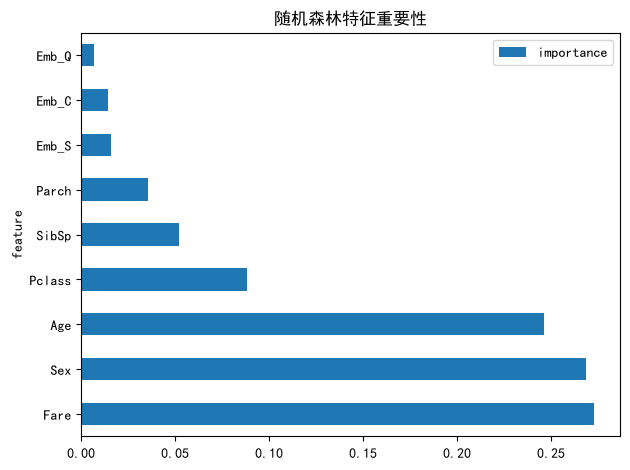

In [23]:
importance_df.plot(kind='barh', x='feature', y='importance', title='随机森林特征重要性')
plt.tight_layout()
plt.savefig('rf_feature_importance.png')
plt.show()

In [24]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.84      0.86      0.85       105
           1       0.79      0.77      0.78        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



## 随机森林调参（GridSearchCV）

- 最优参数：max_depth=5, n_estimators=300
- 交叉验证准确率：82.16%
- 调参后测试集准确率：81.01%
- 结论：调参后测试集准确率反而下降，说明默认参数（max_depth=None）更适合本数据集。
  保留默认参数的随机森林（82.12%）作为最终模型。

In [25]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, 20, None]
}

In [26]:
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [10, 15, 20, None],
                         'n_estimators': [100, 200, 300]},
             scoring='accuracy')

In [27]:
print("最优参数：", grid_search.best_params_)
print("最优交叉验证准确率：", grid_search.best_score_)

最优参数： {'max_depth': 10, 'n_estimators': 200}
最优交叉验证准确率： 0.821619225844578


In [28]:
best_rf = grid_search.best_estimator_
best_pred = best_rf.predict(X_test)
print("调参后测试集准确率：", accuracy_score(y_test, best_pred))

调参后测试集准确率： 0.8100558659217877


In [29]:
from sklearn.metrics import classification_report
print(classification_report(y_test, best_pred))

              precision    recall  f1-score   support

           0       0.81      0.88      0.84       105
           1       0.80      0.72      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



In [30]:
import joblib
joblib.dump(rf_model, 'best_rf_model.pkl') 

['best_rf_model.pkl']

## 9.26 XGBoost

In [31]:
from xgboost import XGBClassifier

In [33]:
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [34]:
xgb_pred = xgb_model.predict(X_test)
print("XGBoost准确率：", accuracy_score(y_test, xgb_pred))

XGBoost准确率： 0.7932960893854749


In [35]:
from sklearn.metrics import classification_report
print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       0.82      0.83      0.82       105
           1       0.75      0.74      0.75        74

    accuracy                           0.79       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.79      0.79      0.79       179



In [36]:
from sklearn.model_selection import GridSearchCV

param_grid_xgb = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample': [0.8, 1.0]
}

grid_xgb = GridSearchCV(
    XGBClassifier(random_state=42, eval_metric='logloss'),
    param_grid_xgb,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_xgb.fit(X_train, y_train)

print("最优参数：", grid_xgb.best_params_)
print("最优交叉验证准确率：", grid_xgb.best_score_)

最优参数： {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}
最优交叉验证准确率： 0.8426770412685904


In [37]:
best_xgb = grid_xgb.best_estimator_
best_xgb_pred = best_xgb.predict(X_test)
print("XGBoost调参后测试集准确率：", accuracy_score(y_test, best_xgb_pred))

XGBoost调参后测试集准确率： 0.8044692737430168


In [38]:
from sklearn.metrics import classification_report
print(classification_report(y_test, best_xgb_pred))

              precision    recall  f1-score   support

           0       0.80      0.89      0.84       105
           1       0.81      0.69      0.74        74

    accuracy                           0.80       179
   macro avg       0.81      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



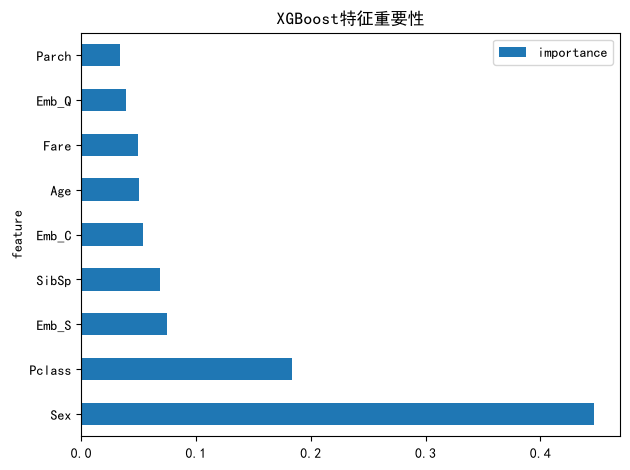

In [39]:
importance_df_xgb = pd.DataFrame({
    'feature': X.columns,
    'importance': best_xgb.feature_importances_
}).sort_values('importance', ascending=False)

importance_df_xgb.plot(kind='barh', x='feature', y='importance', title='XGBoost特征重要性')
plt.tight_layout()
plt.savefig('xgb_feature_importance.png')
plt.show()

In [40]:
import joblib
joblib.dump(best_xgb, 'xgb_model.pkl')

['xgb_model.pkl']

## 9月26日：XGBoost

### 模型结果

- 默认参数：79.30%（严重过拟合）
- 调参后最优参数：learning_rate=0.05, max_depth=3, n_estimators=200, subsample=0.8
- 调参后测试集准确率：80.45%
- 生还类别 F1：0.74，召回率：0.69

### 三模型最终对比

| 模型 | 准确率 | 生还 F1 | 生还召回率 |
|------|--------|---------|-----------|
| 逻辑回归 | 81.06% | 0.76 | 0.74 |
| 随机森林（默认） | 82.12% | 0.78 | 0.77 |
| XGBoost（调参后） | 80.45% | 0.74 | 0.69 |

### 特征重要性对比（随机森林 vs XGBoost）

| 特征 | 随机森林排名 | XGBoost排名 |
|------|-------------|-------------|
| Fare | 第1（0.27） | 第7（0.05） |
| Sex | 第2（0.26） | 第1（0.45） |
| Age | 第3（0.25） | 第6（0.05） |
| Pclass | 第4（0.09） | 第2（0.18） |

### 结论

1. **随机森林在准确率、F1、召回率上全面领先，是最终选择。**
2. XGBoost 默认参数在小数据集上严重过拟合，调参后虽有提升（79.30%→80.45%），但仍不如随机森林（82.12%）。
3. 两个模型对特征重要性的评估存在显著差异：随机森林认为 Fare、Sex、Age 三分天下，XGBoost 认为 Sex 一家独大。这说明不同模型对特征重要性的计算方式不同，模型结论需要交叉验证。
4. 模型选择没有"银弹"，必须根据数据规模和业务需求来决定。在小数据集上，随机森林的"并行投票"机制比 XGBoost 的"串行纠错"更稳健。